# 03 — Friction indicators and session features

Synthetic data only. Seed 42; session-level analysis. Ground truth is reserved for evaluation.

## Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests

## Config

In [2]:
ROOT = Path.cwd() if (Path.cwd() / 'requirements.txt').exists() else Path.cwd().parent
RAW = ROOT / 'data' / 'raw'
PROCESSED = ROOT / 'data' / 'processed'
PROCESSED.mkdir(parents=True, exist_ok=True)
SEED = 42
ALPHA, POWER = 0.05, 0.80
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')
pd.set_option('display.max_columns', 50)

## Data Cleaning and Preprocessing

In [3]:
events = pd.read_csv(RAW / 'events.csv')
sessions = pd.read_csv(RAW / 'sessions.csv')

In [4]:
for name, df in [('events', events), ('sessions', sessions)]:
    print(f'{name}: Total Rows: {len(df):,}; Total Columns: {df.shape[1]}')
    display(df.isna().sum().rename('null_count').to_frame())

events: Total Rows: 212,476; Total Columns: 14


,null_count
event_id,0
user_id,0
session_id,0
event_timestamp,0
event_name,0
page_name,0
product_id,131791
click_count,0
duration_seconds,89320
error_type,207395


sessions: Total Rows: 20,000; Total Columns: 12


,null_count
session_id,0
user_id,0
scenario,0
ground_truth_friction,0
ground_truth_suspicious,0
purchased,0
reached_cart,0
reached_checkout,0
device_type,0
acquisition_channel,0


Optional product, duration, error, payment and navigation telemetry is structurally missing. Preserve it. Required identifiers/timestamps must be complete; fail instead of silently dropping records. No `dropna` is justified on these files.

In [5]:
assert events[['event_id', 'user_id', 'session_id', 'event_timestamp', 'event_name']].notna().all().all()
assert sessions[['session_id', 'user_id']].notna().all().all()
for name, df, key in [('events', events, 'event_id'), ('sessions', sessions, 'session_id')]:
    print(f'{name}: Duplicate rows: {df.duplicated().sum()}; Duplicate IDs: {df[key].duplicated().sum()}')
    duplicates = df[df.duplicated(key, keep=False)]
    assert not duplicates.drop_duplicates().duplicated(key).any(), 'Conflicting duplicate IDs require review'

events: Duplicate rows: 0; Duplicate IDs: 0


sessions: Duplicate rows: 0; Duplicate IDs: 0


Only exact repeats of an ID may be deduplicated, after confirming they agree. Distinct events, including repeated clicks and tied timestamps, remain valid.

In [6]:
events = events.drop_duplicates('event_id').copy()
sessions = sessions.drop_duplicates('session_id').copy()
events['event_timestamp'] = pd.to_datetime(events['event_timestamp'], errors='coerce')
assert events.event_timestamp.notna().all(), 'Invalid timestamps'

In [7]:
for df in [events, sessions]:
    df.info()
    display(df.describe(include='number'))

<class 'pandas.DataFrame'>
RangeIndex: 212476 entries, 0 to 212475
Data columns (total 14 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   event_id             212476 non-null  str           
 1   user_id              212476 non-null  str           
 2   session_id           212476 non-null  str           
 3   event_timestamp      212476 non-null  datetime64[us]
 4   event_name           212476 non-null  str           
 5   page_name            212476 non-null  str           
 6   product_id           80685 non-null   str           
 7   click_count          212476 non-null  int64         
 8   duration_seconds     123156 non-null  float64       
 9   error_type           5081 non-null    str           
 10  payment_status       20817 non-null   str           
 11  navigation_action    4048 non-null    str           
 12  device_type          212476 non-null  str           
 13  acquisition_channel  2124

,click_count,duration_seconds
count,212476.000000,123156.000000
mean,0.346924,17.225050
std,1.184701,13.632646
min,0.000000,0.100011
25%,0.000000,8.633295
50%,0.000000,13.943835
75%,0.000000,22.070250
max,8.000000,307.097127


<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   session_id                20000 non-null  str    
 1   user_id                   20000 non-null  str    
 2   scenario                  20000 non-null  str    
 3   ground_truth_friction     20000 non-null  int64  
 4   ground_truth_suspicious   20000 non-null  int64  
 5   purchased                 20000 non-null  int64  
 6   reached_cart              20000 non-null  int64  
 7   reached_checkout          20000 non-null  int64  
 8   device_type               20000 non-null  str    
 9   acquisition_channel       20000 non-null  str    
 10  session_duration_seconds  20000 non-null  float64
 11  event_count               20000 non-null  int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 2.6 MB


,ground_truth_friction,ground_truth_suspicious,purchased,reached_cart,reached_checkout,session_duration_seconds,event_count
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,0.216100,0.069250,0.208800,0.820600,0.368650,78.149643,10.623800
std,0.411594,0.253885,0.406461,0.383696,0.482451,36.289687,5.664634
min,0.000000,0.000000,0.000000,0.000000,0.000000,3.400000,3.000000
25%,0.000000,0.000000,0.000000,1.000000,0.000000,53.020000,7.000000
50%,0.000000,0.000000,0.000000,1.000000,0.000000,74.340000,9.000000
75%,0.000000,0.000000,0.000000,1.000000,1.000000,99.945000,12.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,258.600000,40.000000


In [8]:
allowed = {'session_start', 'homepage_view', 'search', 'product_view', 'add_to_cart',
           'cart_view', 'remove_from_cart', 'checkout_start', 'payment_attempt', 'purchase',
           'click', 'back_navigation', 'page_error', 'payment_failure', 'payment_success', 'session_exit'}
assert set(events.event_name) <= allowed
assert (events.duration_seconds.dropna() >= 0).all() and (events.click_count >= 0).all()
assert set(events.session_id) == set(sessions.session_id)
assert events.groupby('session_id').event_timestamp.apply(lambda x: x.is_monotonic_increasing).all()
context = events.merge(sessions[['session_id', 'user_id', 'device_type', 'acquisition_channel']],
                       on='session_id', suffixes=('', '_session'), validate='many_to_one')
for col in ['user_id', 'device_type', 'acquisition_channel']:
    assert context[col].eq(context[col + '_session']).all()
print('Required values, timestamps, nonnegative telemetry, event types and context: passed')

Required values, timestamps, nonnegative telemetry, event types and context: passed


In [9]:
events = events.sort_values(['session_id', 'event_timestamp'], kind='stable').reset_index(drop=True)
events['event_position'] = np.arange(len(events))
counts = pd.crosstab(events.session_id, events.event_name).reindex(sessions.session_id, fill_value=0)
elapsed = events.groupby('session_id').event_timestamp.agg(['min', 'max'])
elapsed['duration'] = (elapsed['max'] - elapsed['min']).dt.total_seconds()
audit = sessions.set_index('session_id')
assert counts.sum(axis=1).eq(audit.event_count).all()
for event, field in [('purchase', 'purchased'), ('add_to_cart', 'reached_cart'), ('checkout_start', 'reached_checkout')]:
    assert counts[event].gt(0).astype(int).eq(audit[field]).all()
timing_error = (elapsed.duration - audit.session_duration_seconds).abs()
assert timing_error.max() <= 1.01, 'Timestamp precision discrepancy exceeds one second'
assert counts.session_start.eq(1).all()
assert events.groupby('session_id').first().event_name.eq('session_start').all()
terminal = events.groupby('session_id').last().event_name
print('Sessions with final event other than purchase/exit:', int((~terminal.isin(['purchase', 'session_exit'])).sum()))
print('Purchase sessions without payment_attempt:', int((counts.purchase.gt(0) & counts.payment_attempt.eq(0)).sum()))
print(f'Maximum duration discrepancy: {timing_error.max():.2f} seconds (timestamp rounding)')
print(f'Repeated user IDs across sessions: {sessions.user_id.duplicated().sum():,}')

Sessions with final event other than purchase/exit: 1385
Purchase sessions without payment_attempt: 473
Maximum duration discrepancy: 0.95 seconds (timestamp rounding)
Repeated user IDs across sessions: 8,997


Indicators use observed telemetry only: repeated clicks means a click event with at least 3 clicks; long page means duration above 30 seconds; other flags require at least one relevant event, except repeated checkout requires at least 2 starts. Thresholds are analytical choices, not learned from synthetic labels.

In [10]:
features = sessions[['session_id', 'user_id', 'device_type', 'acquisition_channel']].set_index('session_id').copy()
features['total_events'] = counts.sum(axis=1)
features['session_duration'] = elapsed.duration
features['purchased'] = counts.purchase.gt(0).astype(int)
for feature, event in {'product_views':'product_view', 'cart_additions':'add_to_cart',
                       'back_navigation_count':'back_navigation', 'payment_failure_count':'payment_failure',
                       'error_count':'page_error', 'checkout_attempts':'checkout_start', 'payment_attempts':'payment_attempt'}.items():
    features[feature] = counts[event]
features['repeated_click_count'] = (events.event_name.eq('click') & events.click_count.ge(3)).groupby(events.session_id).sum()
features['long_page_count'] = events.duration_seconds.gt(30).groupby(events.session_id).sum()
features['unique_pages'] = events.groupby('session_id').page_name.nunique()
features['median_event_interval'] = events.groupby('session_id').event_timestamp.diff().dt.total_seconds().groupby(events.session_id).median()
features['event_rate_per_minute'] = features.total_events / (features.session_duration / 60)
features['checkout_duration'] = events.duration_seconds.where(events.page_name.eq('checkout')).groupby(events.session_id).sum(min_count=1)

`checkout_duration` sums recorded checkout-page duration signals; absent telemetry remains missing and overlapping signals may overstate wall-clock time. Model-safe features use fixed browsing event and page whitelists, excluding purchase, payment outcomes, exits, and payment/confirmation pages. Browsing rate is (events minus 1) / elapsed minutes; zero elapsed time leaves the rate undefined for training-only imputation. Full-session aggregates are descriptive and never enter the model. Detection is retrospective, not a prediction before purchase.

In [11]:
browse_names = ['homepage_view', 'search', 'product_view', 'add_to_cart', 'cart_view',
                'remove_from_cart', 'checkout_start', 'click', 'back_navigation', 'page_error']
browse_pages = ['homepage', 'search', 'product', 'cart', 'checkout']
browse = events[events.event_name.isin(browse_names) & events.page_name.isin(browse_pages)].copy()
bg = browse.groupby('session_id')
features['browse_event_count'] = bg.size()
features['browse_clicks'] = bg.click_count.sum()
features['browse_unique_pages'] = bg.page_name.nunique()
features['browse_duration_seconds'] = (bg.event_timestamp.max() - bg.event_timestamp.min()).dt.total_seconds()
features['browse_median_interval'] = bg.event_timestamp.diff().dt.total_seconds().groupby(browse.session_id).median()
features['browse_rate_per_minute'] = (features.browse_event_count - 1) * 60 / features.browse_duration_seconds.replace(0, np.nan)
features['browse_max_page_seconds'] = bg.duration_seconds.max()
for event in ['product_view', 'add_to_cart', 'back_navigation', 'page_error', 'checkout_start']:
    features['browse_' + event + '_count'] = browse.event_name.eq(event).groupby(browse.session_id).sum()
features['browse_repeated_click_count'] = (browse.event_name.eq('click') & browse.click_count.ge(3)).groupby(browse.session_id).sum()

In [12]:
flags = {'repeated_clicks': 'repeated_click_count', 'payment_failures': 'payment_failure_count',
         'back_navigation': 'back_navigation_count', 'long_page': 'long_page_count',
         'technical_errors': 'error_count', 'repeated_checkout': 'checkout_attempts'}
for flag, source in flags.items():
    features[flag] = features[source].ge(2 if flag == 'repeated_checkout' else 1).astype(int)
features = features.reset_index()
assert features.session_id.is_unique and len(features) == len(sessions)
features.to_csv(PROCESSED / 'session_features.csv', index=False)

## Column Description

One line per loaded/derived column; identifiers are linkage fields and synthetic labels are evaluation metadata only.

In [13]:
for name, df in [('events', events), ('sessions', sessions), ('session_features', features)]:
    display(Markdown('### ' + name + '\n' + '\n'.join(f'- `{c}` [{df[c].dtype}]' for c in df.columns)))

### events
- `event_id` [str]
- `user_id` [str]
- `session_id` [str]
- `event_timestamp` [datetime64[us]]
- `event_name` [str]
- `page_name` [str]
- `product_id` [str]
- `click_count` [int64]
- `duration_seconds` [float64]
- `error_type` [str]
- `payment_status` [str]
- `navigation_action` [str]
- `device_type` [str]
- `acquisition_channel` [str]
- `event_position` [int64]

### sessions
- `session_id` [str]
- `user_id` [str]
- `scenario` [str]
- `ground_truth_friction` [int64]
- `ground_truth_suspicious` [int64]
- `purchased` [int64]
- `reached_cart` [int64]
- `reached_checkout` [int64]
- `device_type` [str]
- `acquisition_channel` [str]
- `session_duration_seconds` [float64]
- `event_count` [int64]

### session_features
- `session_id` [str]
- `user_id` [str]
- `device_type` [str]
- `acquisition_channel` [str]
- `total_events` [int64]
- `session_duration` [float64]
- `purchased` [int64]
- `product_views` [int64]
- `cart_additions` [int64]
- `back_navigation_count` [int64]
- `payment_failure_count` [int64]
- `error_count` [int64]
- `checkout_attempts` [int64]
- `payment_attempts` [int64]
- `repeated_click_count` [int64]
- `long_page_count` [int64]
- `unique_pages` [int64]
- `median_event_interval` [float64]
- `event_rate_per_minute` [float64]
- `checkout_duration` [float64]
- `browse_event_count` [int64]
- `browse_clicks` [int64]
- `browse_unique_pages` [int64]
- `browse_duration_seconds` [float64]
- `browse_median_interval` [float64]
- `browse_rate_per_minute` [float64]
- `browse_max_page_seconds` [float64]
- `browse_product_view_count` [int64]
- `browse_add_to_cart_count` [int64]
- `browse_back_navigation_count` [int64]
- `browse_page_error_count` [int64]
- `browse_checkout_start_count` [int64]
- `browse_repeated_click_count` [int64]
- `repeated_clicks` [int64]
- `payment_failures` [int64]
- `back_navigation` [int64]
- `long_page` [int64]
- `technical_errors` [int64]
- `repeated_checkout` [int64]

## EDA

In [14]:
rows = []
for flag in flags:
    a, b = features[features[flag].eq(1)], features[features[flag].eq(0)]
    rows.append({'indicator': flag, 'affected_sessions': len(a), 'unaffected_sessions': len(b),
                 'affected_pct': 100 * len(a) / len(features),
                 'affected_purchase_pct': 100 * a.purchased.mean(), 'unaffected_purchase_pct': 100 * b.purchased.mean(),
                 'affected_median_duration_seconds': a.session_duration.median(),
                 'unaffected_median_duration_seconds': b.session_duration.median()})
friction = pd.DataFrame(rows).sort_values('affected_sessions', ascending=False)
display(friction.round(2))
friction.to_csv(PROCESSED / 'friction_comparison.csv', index=False)

,indicator,affected_sessions,unaffected_sessions,affected_pct,affected_purchase_pct,unaffected_purchase_pct,affected_median_duration_seconds,unaffected_median_duration_seconds
3,long_page,10715,9285,53.58,25.80,15.20,85.0,62.0
1,payment_failures,3496,16504,17.48,41.91,16.43,105.0,67.0
2,back_navigation,2124,17876,10.62,21.52,20.80,123.0,69.0
5,repeated_checkout,1409,18591,7.04,23.07,20.71,127.0,71.0
0,repeated_clicks,1379,18621,6.90,34.30,19.89,115.0,71.0
4,technical_errors,414,19586,2.07,19.57,20.91,86.0,74.0


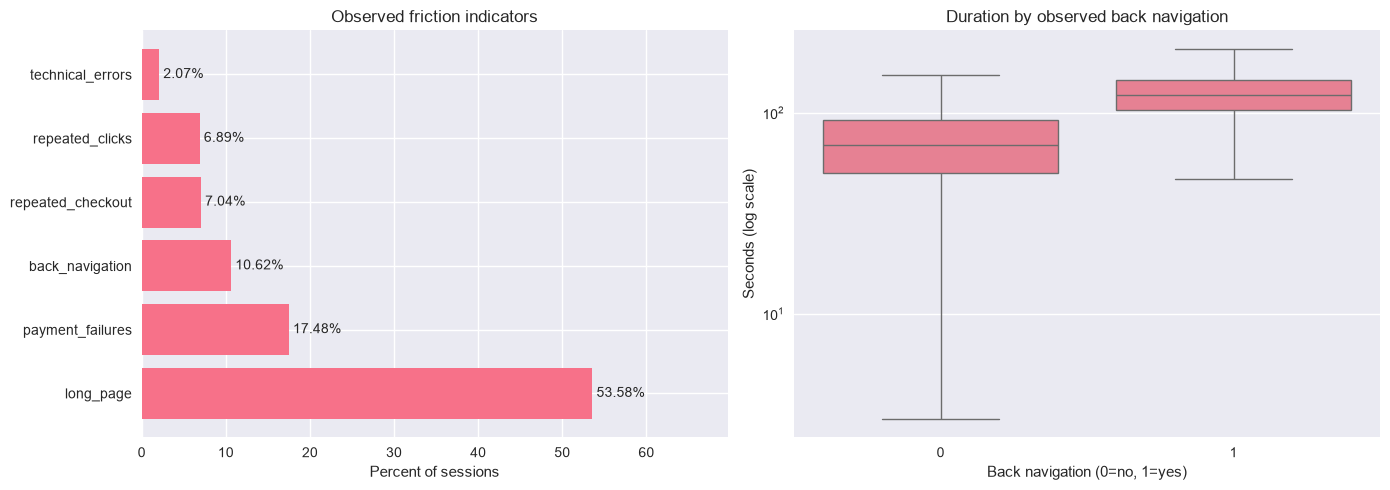

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].barh(friction.indicator, friction.affected_pct)
ax[0].bar_label(ax[0].containers[0], labels=[f'{v:.2f}%' for v in friction.affected_pct], padding=3)
ax[0].set(title='Observed friction indicators', xlabel='Percent of sessions', xlim=(0, max(friction.affected_pct)*1.3))
sns.boxplot(data=features, x='back_navigation', y='session_duration', ax=ax[1], showfliers=False)
ax[1].set_yscale('log')
ax[1].set(title='Duration by observed back navigation', xlabel='Back navigation (0=no, 1=yes)', ylabel='Seconds (log scale)')
plt.tight_layout(); plt.show()

## Problem Statement

Quantify observed friction burden and two predeclared associations. These observational synthetic comparisons cannot identify product effects. Multiple indicators can overlap.

## Numbered Questions

### Inference setup
Select one session per user uniformly with seed 42 **before** eligibility filtering, keeping the session as the observational unit while avoiding repeated-user dependence. All sessions remain in descriptive tables. Cross-user independence is an untestable working assumption. Two exploratory tests use alpha=0.05, target power=0.80 and Holm correction across questions. Planning sample sizes are benchmarks, not achieved-power evidence.

In [16]:
inference = features.sample(frac=1, random_state=SEED).drop_duplicates('user_id')
assert inference.user_id.is_unique
print(f'Independent-user session subset: {len(inference):,}')

Independent-user session subset: 11,003


### 1. Do payment-failure sessions have different purchase rates among payment-attempt sessions?
 Objective: compare affected minus unaffected purchase probability, conditional on at least one payment attempt.
 H0: $p_1=p_0$; H1: $p_1\ne p_0$. Alpha=0.05; power=0.80.
 `binary_sample_size` uses an equal-group normal approximation, planning $p_0=0.50$, $p_1=0.55$ (5 percentage points):
 $$n=\left\lceil\frac{(z_{1-\alpha/2}+z_{\mathrm{power}})^2[p_0(1-p_0)+p_1(1-p_1)]}{(p_1-p_0)^2}\right\rceil.$$
 This benchmark assumes independent Bernoulli observations; both groups must meet it. Use `proportions_ztest` if every observed outcome cell is at least 10, otherwise Fisher's exact test. Effect is the risk difference with a 95% Newcombe interval; the fallback statistic is an odds ratio.

In [17]:
def binary_sample_size(p0=0.50, p1=0.55, alpha=ALPHA, power=POWER):
    z = stats.norm.ppf(1-alpha/2) + stats.norm.ppf(power)
    return int(np.ceil(z*z*(p0*(1-p0)+p1*(1-p1))/(p1-p0)**2))

In [18]:
eligible = inference[inference.payment_attempts.gt(0)]
groups = [eligible.loc[eligible.payment_failures.eq(v), 'purchased'] for v in [1, 0]]
successes = np.array([g.sum() for g in groups])
sizes = np.array([len(g) for g in groups])
table = np.column_stack([successes, sizes-successes])
assert (sizes > 0).all() and eligible.purchased.isin([0, 1]).all()
print('Outcome counts [purchase, no purchase]:', table.tolist())
print('Per-group planning requirement:', binary_sample_size(), '; actual:', sizes.tolist(),
      '; adequate:', bool((sizes >= binary_sample_size()).all()))
if (table >= 10).all():
    statistic1, p1 = proportions_ztest(successes, sizes)
    method1 = 'two-sided proportions z-test'
else:
    statistic1, p1 = stats.fisher_exact(table)
    method1 = 'two-sided Fisher exact test (odds-ratio statistic)'
difference1 = successes[0]/sizes[0] - successes[1]/sizes[1]
ci1 = confint_proportions_2indep(successes[0], sizes[0], successes[1], sizes[1], method='newcomb', compare='diff')
print(f'{method1}: statistic={statistic1:.4f}, p={p1:.6g}')
print(f'Risk difference: {100*difference1:.2f} percentage points; 95% CI [{100*ci1[0]:.2f}, {100*ci1[1]:.2f}]')

Outcome counts [purchase, no purchase]: [[777, 1152], [1256, 503]]
Per-group planning requirement: 1562 ; actual: [1929, 1759] ; adequate: True
two-sided proportions z-test: statistic=-18.9813, p=2.43494e-80
Risk difference: -31.12 percentage points; 95% CI [-34.12, -28.04]


### 2. Does mean log session duration differ with back navigation?
 Objective: compare log durations for sessions with versus without back navigation.
 H0: $E[\log D\mid B=1]=E[\log D\mid B=0]$; H1: unequal means. Alpha=0.05; power=0.80.
 `continuous_sample_size` uses a prespecified standardized effect $d=0.20$:
 $$n=\left\lceil 2(z_{1-\alpha/2}+z_{\mathrm{power}})^2/d^2\right\rceil.$$
 This normal approximation is an equal-group planning benchmark. Positive finite durations, skew, tail behavior, group sizes and Levene variance diagnostics are checked. Welch's t-test avoids assuming equal variances; large independent groups support its mean approximation, not a claim that the underlying population is normal. If either group has fewer than 30 observations or extreme log-scale tails, report descriptively and withhold the test. Report mean-log difference, Cohen's d and a Welch 95% CI, plus the corresponding geometric-mean ratio.

In [19]:
def continuous_sample_size(d=0.20, alpha=ALPHA, power=POWER):
    z = stats.norm.ppf(1-alpha/2) + stats.norm.ppf(power)
    return int(np.ceil(2*z*z/d**2))

In [20]:
assert inference.session_duration.gt(0).all() and np.isfinite(inference.session_duration).all()
x, y = [np.log(inference.loc[inference.back_navigation.eq(v), 'session_duration']).to_numpy() for v in [1, 0]]
diagnostics = pd.DataFrame({'n':[len(x),len(y)], 'skew':[stats.skew(x),stats.skew(y)],
                             'excess_kurtosis':[stats.kurtosis(x),stats.kurtosis(y)]}, index=['back','no_back'])
display(diagnostics)
print('Levene p:', stats.levene(x, y, center='median').pvalue)
print('Per-group planning requirement:', continuous_sample_size(), '; adequate:', min(len(x),len(y)) >= continuous_sample_size())
t_ok = min(len(x),len(y)) >= 30 and diagnostics['skew'].abs().max() < 2 and diagnostics.excess_kurtosis.max() < 10

,n,skew,excess_kurtosis
back,1189,-0.215147,-0.077886
no_back,9814,-1.406842,2.830417


Levene p: 1.8844242455448032e-70
Per-group planning requirement: 393 ; adequate: True


In [21]:
difference2 = x.mean() - y.mean()
if t_ok:
    statistic2, p2 = stats.ttest_ind(x, y, equal_var=False)
    vx, vy = x.var(ddof=1)/len(x), y.var(ddof=1)/len(y)
    degrees = (vx+vy)**2 / (vx**2/(len(x)-1)+vy**2/(len(y)-1))
    margin = stats.t.ppf(1-ALPHA/2, degrees) * np.sqrt(vx+vy)
    ci2 = (difference2-margin, difference2+margin)
    pooled_sd = np.sqrt(((len(x)-1)*x.var(ddof=1)+(len(y)-1)*y.var(ddof=1))/(len(x)+len(y)-2))
    p2_text = 'p<1e-300' if p2 == 0 else f'p={p2:.6g}'
    print(f'Welch t={statistic2:.4f}, df={degrees:.1f}, {p2_text}; Cohen d={difference2/pooled_sd:.4f}')
    print(f'Mean log difference={difference2:.4f}; 95% CI {ci2}')
    print(f'Geometric mean ratio={np.exp(difference2):.3f}; 95% CI [{np.exp(ci2[0]):.3f}, {np.exp(ci2[1]):.3f}]')
else:
    p2 = np.nan
    print('Assumptions insufficient: descriptive mean log difference only:', difference2)

Welch t=72.1078, df=3152.9, p<1e-300; Cohen d=1.2020
Mean log difference=0.6658; 95% CI (np.float64(0.6476513481159483), np.float64(0.6838570312737939))
Geometric mean ratio=1.946; 95% CI [1.911, 1.982]


In [22]:
raw_p = np.array([p1, p2])
finite = np.isfinite(raw_p)
adjusted = np.full(2, np.nan)
adjusted[finite] = multipletests(raw_p[finite], alpha=ALPHA, method='holm')[1]
for question, value in enumerate(adjusted, 1):
    conclusion = 'association detected' if value < ALPHA else 'insufficient evidence of a difference'
    value_text = 'p<1e-300' if value == 0 else f'p={value:.6g}'
    print(f'Question {question}: Holm {value_text}; {conclusion if np.isfinite(value) else "test withheld"}.')
print('Intervals are marginal 95% intervals, not simultaneous family-wise intervals. No causal interpretation.')

Question 1: Holm p=2.43494e-80; association detected.
Question 2: Holm p<1e-300; association detected.
Intervals are marginal 95% intervals, not simultaneous family-wise intervals. No causal interpretation.


## Summary

Use the prevalence and cohort table to prioritize investigation. Payment comparisons condition on an opportunity to attempt payment; duration comparisons use log seconds and one session per user. Inspect reported planning adequacy and Holm-adjusted conclusions before interpreting associations.

In [23]:
display(Markdown(f'**Observed burden:** `{friction.iloc[0].indicator}` affects {int(friction.iloc[0].affected_sessions):,} sessions ({friction.iloc[0].affected_pct:.2f}%). Payment-failure purchase-rate difference: {difference1*100:.2f} percentage points. Back-navigation geometric-mean duration ratio: {np.exp(difference2):.3f}. These are associations.'))

**Observed burden:** `long_page` affects 10,715 sessions (53.58%). Payment-failure purchase-rate difference: -31.12 percentage points. Back-navigation geometric-mean duration ratio: 1.946. These are associations.

## Insights

Review payment error codes, repeated-click locations and navigation loops. Long duration may reflect interest or an idle tab; clicks alone do not prove frustration. Shared user IDs prevent treating all sessions as independent observations. Confounding, overlapping indicators and synthetic generation limit interpretation. Exported IDs and purchase outcomes are for linkage/descriptions only; Notebook 04 has an explicit safe input allowlist.